# パイロット：A社の企業内類似度（出願日 2020 年）

CLAUDE.md の Stage 1 に沿って、**発明を実施するための形態**の本文を TF-IDF（文字 n-gram）＋コサイン類似度で比較する。
今回は 1 社のみのため、すべて企業内（`intra`）ペアである。

- 結果は探索的なもの。分割出願など交絡の統制は Stage 2 で行うため、ここでは結論を出さない
- 企業名は出力しない（A社）

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import connect

DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)

# ---- 設定 ----
APPLICANT_NO = "390026620"   # 出願人番号（A社）。実名は出力しない
FILING_YEAR = "2020"         # 出願日の年
MIN_CHARS = 1000             # 本文がこれより短いものは除外
NGRAM = (2, 3)
MIN_DF, MAX_DF = 2, 0.5

plt.rcParams["font.family"] = ["Yu Gothic", "Meiryo", "MS Gothic", "sans-serif"]
sns.set_theme(style="whitegrid", font=plt.rcParams["font.family"][0])

## 1. 母集団の取得（1-1）

出願人番号・出願日・筆頭 FI（A63F7/02 系 / A63F5/04 系）・公開特許公報(`kind_of_jp = 'A'`) で絞る。
2022 年以降の公開分は FI の先頭に `JP` が付くため正規表現で判定する。

In [ ]:
SQL = r'''
SELECT b.publication_number, b.application_number, b.application_date, b.publication_date,
       b.applicant1_number AS applicant_number, b.agent1_number AS agent_number,
       b.invention_title, b.classification_national AS fi_codes,
       t.description_of_embodiments AS body
FROM pupa_application_basic_info b
JOIN pupa_text_info t USING (publication_number)
WHERE b.kind_of_jp = 'A'
  AND b.applicant1_number = %(app)s
  AND b.application_date LIKE %(year)s
  AND b.classification_national ~ '^(JP\s+)?A63F(7/02|5/04)'
'''
with connect() as conn:
    cur = conn.execute(SQL, {"app": APPLICANT_NO, "year": FILING_YEAR + "%"})
    raw = pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])
print("取得件数:", len(raw))
raw.drop(columns="body").head()

## 2. 前処理と除外

In [ ]:
df = raw.copy()
df = df.replace("None", np.nan)
df["body"] = df["body"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()
df["text_len"] = df["body"].str.len()

for c in ["application_date", "publication_date"]:
    df[c] = pd.to_datetime(df[c], format="%Y%m%d", errors="coerce")

excluded = df[df["text_len"] < MIN_CHARS]
pop = df[df["text_len"] >= MIN_CHARS].drop_duplicates("publication_number").reset_index(drop=True)
print(f"取得 {len(raw)} 件 / 本文なし・短文で除外 {len(excluded)} 件 / 対象 {len(pop)} 件")
print("除外分の本文長（文字）:", excluded["text_len"].describe()[["min", "50%", "max"]].round(0).to_dict())
print("除外分の出願月:", excluded["application_date"].dt.strftime("%Y-%m").value_counts().sort_index().to_dict())
print(pop["text_len"].describe().round(0).to_string())

pop.drop(columns="body").to_parquet(DATA / "population.parquet", index=False)

取得 160 件 / 本文なし・短文で除外 38 件 / 対象 122 件
除外分の本文長（文字）: {'min': 30.0, '50%': 118.0, 'max': 323.0}
除外分の出願月: {'2020-06': 3, '2020-07': 16, '2020-08': 7, '2020-09': 3, '2020-10': 3, '2020-11': 6}
count       122.0
mean      72812.0
std       41749.0
min       12371.0
25%       40834.0
50%       65858.0
75%       99653.0
max      201650.0


## 3. TF-IDF ベクトル化（1-2）

文字 2〜3-gram、`sublinear_tf`。業界の定型句は IDF で重みが下がり、さらに `max_df` で出現率の高すぎる n-gram を落とす。

In [ ]:
vec = TfidfVectorizer(
    analyzer="char", ngram_range=NGRAM, min_df=MIN_DF, max_df=MAX_DF,
    sublinear_tf=True, dtype=np.float32,
)
X = vec.fit_transform(pop["body"])
print("文書数 x 特徴量数:", X.shape, " 非ゼロ要素:", X.nnz)

文書数 x 特徴量数: (122, 124825)  非ゼロ要素: 1485127


## 4. コサイン類似度（1-3）

TF-IDF は L2 正規化済みなので、内積がコサイン類似度になる。全ペア総当たり（パイロット規模）。

In [ ]:
S = np.clip((X @ X.T).toarray(), 0.0, 1.0)  # float32 の丸めで 1 を超える分を切る
np.fill_diagonal(S, np.nan)

iu = np.triu_indices(len(pop), k=1)
pairs = pd.DataFrame({
    "pub_no_a": pop["publication_number"].values[iu[0]],
    "pub_no_b": pop["publication_number"].values[iu[1]],
    "cosine": S[iu].astype(np.float32),
    "same_agent": (pop["agent_number"].values[iu[0]] == pop["agent_number"].values[iu[1]]),
    "same_filing_date": (pop["application_date"].values[iu[0]] == pop["application_date"].values[iu[1]]),
})
pairs["pair_scope"] = "intra"
pairs.to_parquet(DATA / "pair_scores.parquet", index=False)
print("ペア数:", len(pairs))
pairs["cosine"].describe().round(3).to_string()

ペア数: 7381


'count    7381.000\nmean        0.147\nstd         0.249\nmin         0.007\n25%         0.032\n50%         0.054\n75%         0.110\nmax         1.000'

## 5. 確認（1-4）

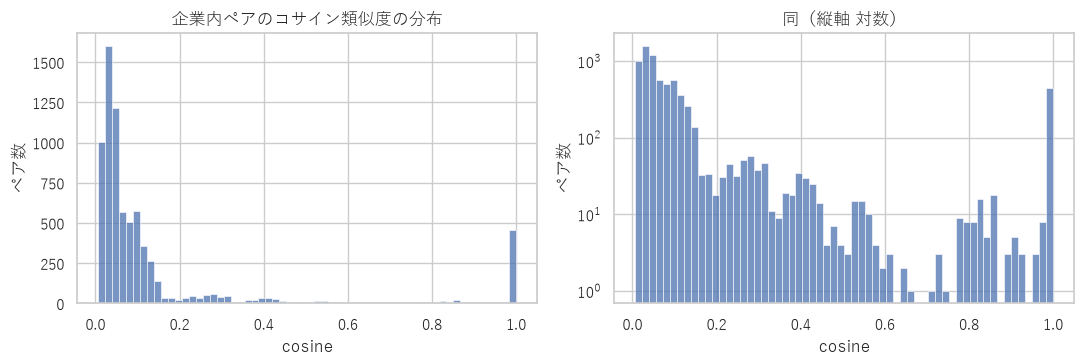

0.500    0.054
0.900    0.369
0.990    1.000
0.999    1.000


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(pairs["cosine"], bins=60, ax=ax[0])
ax[0].set(title="企業内ペアのコサイン類似度の分布", xlabel="cosine", ylabel="ペア数")
sns.histplot(pairs["cosine"], bins=60, ax=ax[1])
ax[1].set(yscale="log", title="同（縦軸 対数）", xlabel="cosine", ylabel="ペア数")
plt.tight_layout(); plt.show()

q = pairs["cosine"].quantile([.5, .9, .99, .999]).round(3)
print(q.to_string())

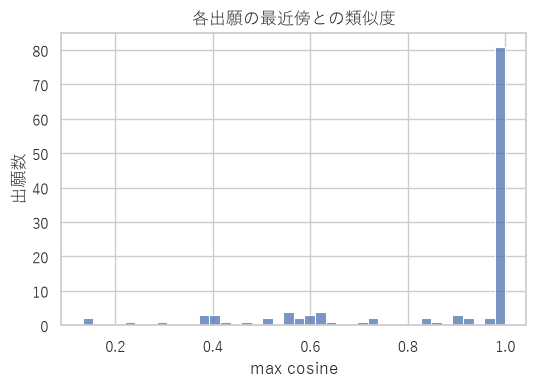

最近傍の類似度 >= 0.5: 110 件 (90.2%)
最近傍の類似度 >= 0.7: 94 件 (77.0%)
最近傍の類似度 >= 0.9: 88 件 (72.1%)


In [ ]:
# 各出願について、最も似ている他の出願との類似度
pop["max_cosine"] = np.nanmax(S, axis=1)
pop["nearest"] = pop["publication_number"].values[np.nanargmax(S, axis=1)]

fig, ax = plt.subplots(figsize=(6, 3.8))
sns.histplot(pop["max_cosine"], bins=40, ax=ax)
ax.set(title="各出願の最近傍との類似度", xlabel="max cosine", ylabel="出願数")
plt.show()

for th in [0.5, 0.7, 0.9]:
    print(f"最近傍の類似度 >= {th}: {(pop['max_cosine'] >= th).sum()} 件 ({(pop['max_cosine'] >= th).mean():.1%})")

In [ ]:
# 類似度の上位ペア
meta = pop.set_index("publication_number")[["application_date", "invention_title", "text_len"]]
top = pairs.sort_values("cosine", ascending=False).head(20).copy()
for s in ["a", "b"]:
    top[f"title_{s}"] = top[f"pub_no_{s}"].map(meta["invention_title"])
    top[f"len_{s}"] = top[f"pub_no_{s}"].map(meta["text_len"])
top[["pub_no_a", "pub_no_b", "cosine", "same_agent", "same_filing_date", "title_a", "title_b", "len_a", "len_b"]]

,pub_no_a,pub_no_b,cosine,same_agent,same_filing_date,title_a,title_b,len_a,len_b
7191,2021186468,2021186469,1.000000,False,True,遊技機,遊技機,121992,121992
1386,2021108969,2021108970,1.000000,False,True,スロットマシン,スロットマシン,22723,22723
1495,2021108970,2021108971,1.000000,False,True,スロットマシン,スロットマシン,22723,22723
1387,2021108969,2021108971,1.000000,False,True,スロットマシン,スロットマシン,22723,22723
7097,2021185993,2021185995,1.000000,False,True,遊技機,遊技機,22504,22504
1165,2021108828,2021108829,1.000000,False,True,遊技機,遊技機,42600,42600
6564,2021159431,2021159432,1.000000,False,True,遊技機,遊技機,125533,125533
6640,2021159515,2021159516,1.000000,False,True,遊技機,遊技機,155828,155828
2821,2021122434,2021122435,1.000000,False,True,遊技機,遊技機,122538,122538
1054,2021108827,2021108829,1.000000,False,True,遊技機,遊技機,42600,42600


上位ペアの本文を並べて目視確認する（先頭と中ほどの一部）。

In [ ]:
body = pop.set_index("publication_number")["body"]

def show(rank, n=300):
    r = top.iloc[rank]
    print(f"[{rank}] cosine={r.cosine:.3f}  {r.pub_no_a} vs {r.pub_no_b}  同日出願={r.same_filing_date}")
    for p in (r.pub_no_a, r.pub_no_b):
        t = body[p]; m = len(t) // 2
        print(f"  {p} 先頭: {t[:n]}")
        print(f"  {p} 中ほど: {t[m:m+n]}")
    print()

for i in range(3):
    show(i)

[0] cosine=1.000  2021186468 vs 2021186469  同日出願=True
  2021186468 先頭: （遊技機10） 本明細書では、各説明箇所において、方向についての定義等が示されていない場合には、遊技機10の方を向いて位置している遊技者から見て、遊技機10から遊技者の手前側に向かう方向を「前」方向とし、その逆方向を「後」方向とする。また、同様に、「左」や「右」等の左右方向及び「上」や「下」等の上下方向も、遊技者から見た場合の左方向や右方向、又は上方向や下方向を意味する。同様に、各部材の説明においても、方向についての定義等が示されていない場合には、各部材を、遊技機10の所定位置に固定した場合における遊技者から見た方向を意味する。 本実施の形態に係る遊技機10としてのスロットマシンを、以下、図１
  2021186468 中ほど: 枚数の最も高いレベル以外の特定のレベルを備える。 具体的には、レベル４は、図３２に示すように、上乗せ高確状態への移行抽選の当選確率も、上乗せ特化ゾーン高確状態への移行抽選の当選確率も、第２ＡＴ通常状態高確状態への移行抽選の当選確率も、他のレベルに比べて低く設定されており、又、レベル５に比べ１ゲームあたりの純増枚数が低く設定されている。 一方、レベル４は、移行抽選の当選確率以外の抽選の当選確率が、他のレベルに比べ高くなるように設定されている。 具体的には、上述したように、上乗せ抽選の当選確率は、他のレベルに比べて高く設定されている。このため、レベル４は、上乗せを獲得しやすいレベルである。 すなわ
  2021186469 先頭: （遊技機10） 本明細書では、各説明箇所において、方向についての定義等が示されていない場合には、遊技機10の方を向いて位置している遊技者から見て、遊技機10から遊技者の手前側に向かう方向を「前」方向とし、その逆方向を「後」方向とする。また、同様に、「左」や「右」等の左右方向及び「上」や「下」等の上下方向も、遊技者から見た場合の左方向や右方向、又は上方向や下方向を意味する。同様に、各部材の説明においても、方向についての定義等が示されていない場合には、各部材を、遊技機10の所定位置に固定した場合における遊技者から見た方向を意味する。 本実施の形態に係る遊技機10としてのスロットマシ

C:\Users\k-fukuzawa\src\patent-similarity-analysis\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
C:\Users\k-fukuzawa\src\patent-similarity-analysis\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


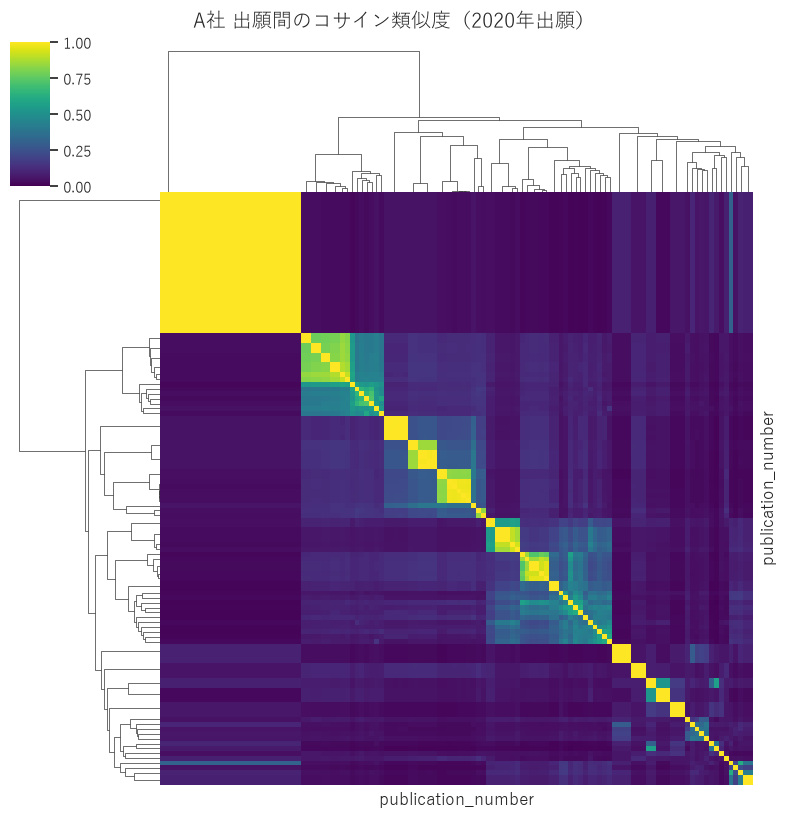

In [ ]:
# 出願ごとの類似度行列（階層クラスタリングで並べ替え）。流用グループのブロック構造を見る
sim = pd.DataFrame(np.nan_to_num(S, nan=1.0), index=pop["publication_number"], columns=pop["publication_number"])
g = sns.clustermap(sim, cmap="viridis", vmin=0, vmax=1, figsize=(8, 8),
                   xticklabels=False, yticklabels=False)
g.fig.suptitle("A社 出願間のコサイン類似度（2020年出願）", y=1.02)
plt.show()

## メモ

- 分割出願・優先権ファミリーは同じ文章になるため、上位ペアの多くがそれに当たる可能性がある（Stage 2 で除外）
- パラメータ（`NGRAM` / `MIN_DF` / `MAX_DF`）を変えて分布が大きく変わらないかを確認する
- 結果の記録は `docs/` に残す